# Q4 — Xu hướng điểm cảm quan (`total_9`) giai đoạn thu hoạch 2012–2017

**Câu hỏi phân tích (bản chốt 08/11 — D2, D4, D5):**  
> *Trong giai đoạn thu hoạch 2012–2017, điểm trung vị `total_9` tăng hay giảm bao nhiêu điểm mỗi năm (CI 95%), và xu hướng đó còn giữ không khi loại bỏ ảnh hưởng của việc cơ cấu quốc gia gửi mẫu thay đổi qua các năm?*

- **Người quan tâm:** Nhà rang xay, người mua theo dõi chất lượng nguồn cung theo thời gian.
- **Phạm vi bước này (Bước 4 — D2):** Tiền xử lý, lọc cửa sổ thời gian 2012–2017 có lý do rõ ràng, lập bảng `pivot_table` `Harvest.Year × Continent.of.Origin`, tính trung bình trượt `rolling(3)` và phần trăm thay đổi `pct_change()` qua từng năm.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.cleaning import convert_types, flag_placeholders, load_raw
from src.config import RANDOM_STATE, SCORE_COLS
from src.features import add_total_score


def major_minor(version: str) -> str:
    return ".".join(version.split(".")[:2])


# TEST: Kiểm tra phiên bản thư viện chuẩn của môi trường coffee
assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
print("Environment OK:", f"numpy={np.__version__}, pandas={pd.__version__}, matplotlib={matplotlib.__version__}")

Environment OK: numpy=1.26.4, pandas=2.1.4, matplotlib=3.8.4


## 1. Preprocessing — Lọc cửa sổ thời gian 2012–2017

### Luồng xử lý dữ liệu
1. **Đọc dữ liệu & chuẩn hóa kiểu:** Dùng `load_raw()` (`keep_default_na=False, na_values=[""]`), `convert_types()` (`Harvest.Year` → `Int64`), và `add_total_score()`.
2. **Lọc loài (`Species == "Arabica"`):** Loại bỏ 28 lô Robusta theo quyết định chung của nhóm.
3. **Loại bỏ bản ghi lỗi `REC_ID = 1310`:** Loại 1 lô Arabica có toàn bộ 9 điểm cảm quan bằng 0 (`zero_all_scores == True`).
4. **Loại bỏ các dòng thiếu `Harvest.Year`:** Có 60 lô Arabica bị thiếu năm thu hoạch (`NA`) → không thể đưa vào phân tích xu hướng theo năm.
5. **Chọn cửa sổ thời gian 2012–2017:**
   - **Giữ giai đoạn 2012–2017:** Mỗi năm có cỡ mẫu đủ lớn để ước lượng trung vị ổn định (**86–352 lô/năm**).
   - **Loại 2009–2011:** Cỡ mẫu quá nhỏ (dưới 40 lô/năm: 2009 có 20 lô, 2010 có 30 lô, 2011 có 35 lô), dễ gây nhiễu khi tính trung vị và tách theo châu lục.
   - **Loại 2018:** Chỉ có **1 lô**, không mang tính đại diện cho cả năm thu hoạch.

In [2]:
tracking = []

df_raw = add_total_score(convert_types(load_raw()))
tracking.append(("1. Dữ liệu thô ban đầu", len(df_raw), 0, "Đọc Coffee_Qlty.csv + add_total_score"))
print(f"Bước 1 - Dữ liệu thô: {len(df_raw)} dòng")

masks = flag_placeholders(df_raw)

df_arabica = df_raw[df_raw["Species"] == "Arabica"].copy()
tracking.append((
    "2. Lọc Species == 'Arabica'",
    len(df_arabica),
    len(df_raw) - len(df_arabica),
    "Loại các lô Robusta",
))
print(f"Bước 2 - Lọc Arabica: {len(df_arabica)} dòng (loại {len(df_raw) - len(df_arabica)})")

df_valid = df_arabica[~masks.loc[df_arabica.index, "zero_all_scores"]].copy()
tracking.append((
    "3. Loại placeholder điểm = 0 (REC_ID 1310)",
    len(df_valid),
    len(df_arabica) - len(df_valid),
    "Loại bản ghi lỗi cảm quan",
))
print(f"Bước 3 - Loại REC_ID 1310: {len(df_valid)} dòng (loại {len(df_arabica) - len(df_valid)})")

df_yr = df_valid.dropna(subset=["Harvest.Year"]).copy()
tracking.append((
    "4. Loại thiếu Harvest.Year (NA)",
    len(df_yr),
    len(df_valid) - len(df_yr),
    "60 lô thiếu năm thu hoạch",
))
print(f"Bước 4 - Có Harvest.Year: {len(df_yr)} dòng (loại {len(df_valid) - len(df_yr)})")

print("\nSố lô theo từng năm trước khi lọc cửa sổ 2012–2017:")
display(df_yr["Harvest.Year"].value_counts().sort_index().to_frame("n_lots"))

df_q4 = df_yr[df_yr["Harvest.Year"].between(2012, 2017)].copy()
tracking.append((
    "5. Giữ cửa sổ 2012–2017",
    len(df_q4),
    len(df_yr) - len(df_q4),
    "Loại 2009–2011 (<40 lô/năm) và 2018 (1 lô)",
))
print(f"Bước 5 - Cửa sổ 2012–2017: {len(df_q4)} dòng (loại {len(df_yr) - len(df_q4)})")

tracking_df = pd.DataFrame(
    tracking, columns=["Bước xử lý", "Số dòng còn lại", "Số dòng bị loại", "Ghi chú"]
)
display(tracking_df)

Bước 1 - Dữ liệu thô: 1339 dòng
Bước 2 - Lọc Arabica: 1311 dòng (loại 28)
Bước 3 - Loại REC_ID 1310: 1310 dòng (loại 1)
Bước 4 - Có Harvest.Year: 1250 dòng (loại 60)

Số lô theo từng năm trước khi lọc cửa sổ 2012–2017:


,n_lots
Harvest.Year,
2009,20
2010,30
2011,35
2012,352
2013,199
2014,245
2015,153
2016,129
2017,86


Bước 5 - Cửa sổ 2012–2017: 1164 dòng (loại 86)


,Bước xử lý,Số dòng còn lại,Số dòng bị loại,Ghi chú
0,1. Dữ liệu thô ban đầu,1339,0,Đọc Coffee_Qlty.csv + add_total_score
1,2. Lọc Species == 'Arabica',1311,28,Loại các lô Robusta
2,3. Loại placeholder điểm = 0 (REC_ID 1310),1310,1,Loại bản ghi lỗi cảm quan
3,4. Loại thiếu Harvest.Year (NA),1250,60,60 lô thiếu năm thu hoạch
4,5. Giữ cửa sổ 2012–2017,1164,86,Loại 2009–2011 (<40 lô/năm) và 2018 (1 lô)


In [3]:
# TEST: Kiểm tra dữ liệu sau Preprocessing của Q4
assert (df_q4["Species"] == "Arabica").all()
assert 1310 not in df_q4["REC_ID"].values
assert df_q4["Harvest.Year"].isna().sum() == 0
assert set(df_q4["Harvest.Year"].unique()) == {2012, 2013, 2014, 2015, 2016, 2017}
assert df_q4["total_9"].isna().sum() == 0
print("All Q4 Preprocessing # TEST checks passed!")

All Q4 Preprocessing # TEST checks passed!

## 2. Analysis — Pivot Table & Cửa sổ thời gian (D2)

- Dùng `pivot_table` (`Harvest.Year × Continent.of.Origin`) với `aggfunc=['median', 'size']` để quan sát đồng thời điểm trung vị `total_9` và sự dịch chuyển cơ cấu số lô theo châu lục qua các năm 2012–2017.
- Tính chuỗi trung vị toàn bộ (`overall`), trung bình trượt 3 năm (`rolling(3, min_periods=2).mean()`) để làm mượt biến động ngắn hạn, và tốc độ thay đổi so với năm trước (`pct_change()`).

In [4]:
d = df_q4.copy()

pv = d.pivot_table(
    index="Harvest.Year",
    columns="Continent.of.Origin",
    values="total_9",
    aggfunc=["median", "size"],
)
print("Pivot table Harvest.Year × Continent.of.Origin (median total_9 và số lô):")
display(pv.round(3))

overall = d.groupby("Harvest.Year")["total_9"].median()
overall_n = d.groupby("Harvest.Year")["total_9"].size()
overall_roll3 = overall.rolling(3, min_periods=2).mean()
overall_pct = overall.pct_change()

overall_summary = pd.DataFrame(
    {
        "n_lots": overall_n,
        "median_total_9": overall,
        "rolling_3y_mean": overall_roll3,
        "pct_change_pct": overall_pct * 100,
    }
)
print("\nTổng hợp xu hướng trung vị total_9 theo năm (2012–2017):")
display(overall_summary.round(3))

Pivot table Harvest.Year × Continent.of.Origin (median total_9 và số lô):


median                                              size  \
Continent.of.Origin  Africa   Asia North America Oceania South America Africa   
Harvest.Year                                                                    
2012                 76.705  74.67        74.430   77.82        75.330   16.0   
2013                 76.410  73.74        74.670     NaN        75.365   21.0   
2014                 75.080  74.66        74.465     NaN        75.570   61.0   
2015                 75.340  75.51        74.590     NaN        75.540   15.0   
2016                 74.700  74.71        75.500     NaN        75.420   10.0   
2017                 75.920  75.08        74.750     NaN        75.410    7.0   

                                                               
Continent.of.Origin  Asia North America Oceania South America  
Harvest.Year                                                   
2012                 16.0         267.0     1.0          52.0  
2013                 35.0          87.0     NaN          56.0  
2014                 33.0         102.0     NaN          49.0  
2015                 41.0          53.0     NaN          44.0  
2016                 18.0          53.0     NaN          48.0  
2017                  9.0          49.0     NaN          21.0


Tổng hợp xu hướng trung vị total_9 theo năm (2012–2017):


,n_lots,median_total_9,rolling_3y_mean,pct_change_pct
Harvest.Year,,,,
2012,352,74.705,NaN,NaN
2013,199,75.000,74.852,0.395
2014,245,75.000,74.902,0.000
2015,153,75.240,75.080,0.320
2016,129,75.260,75.167,0.027
2017,86,75.080,75.193,-0.239


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

years = overall_summary.index.astype(int)
axes[0].plot(years, overall_summary["median_total_9"], marker="o", label="Median total_9")
axes[0].plot(
    years,
    overall_summary["rolling_3y_mean"],
    marker="s",
    linestyle="--",
    label="Rolling 3 năm (min_periods=2)",
)
for x, y, n_val in zip(years, overall_summary["median_total_9"], overall_summary["n_lots"]):
    axes[0].annotate(f"n={n_val}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
axes[0].set_title("Trung vị total_9 toàn bộ giai đoạn 2012–2017")
axes[0].set_xlabel("Harvest.Year")
axes[0].set_ylabel("total_9 (điểm)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

median_by_cont = pv["median"]
for col in median_by_cont.columns:
    axes[1].plot(median_by_cont.index.astype(int), median_by_cont[col], marker="o", label=col)
axes[1].set_title("Trung vị total_9 theo Continent.of.Origin (2012–2017)")
axes[1].set_xlabel("Harvest.Year")
axes[1].set_ylabel("total_9 (điểm)")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

<Figure size 1300x450 with 2 Axes>

In [6]:
# TEST: Kiểm tra kết quả pivot_table, rolling(3) và pct_change()
assert list(pv.index) == [2012, 2013, 2014, 2015, 2016, 2017]
assert pv["size"].sum().sum() == len(df_q4)
assert overall_roll3.iloc[1:].notna().all(), "rolling(3, min_periods=2) phải có giá trị từ năm thứ 2"
assert overall_pct.iloc[1:].notna().all(), "pct_change() phải có giá trị từ năm thứ 2"
print("All Q4 Pivot & Rolling # TEST checks passed!")

All Q4 Pivot & Rolling # TEST checks passed!


## 3. Analysis — Kiểm soát cơ cấu quốc gia (D4) & Bootstrap CI độ dốc (D5)

1. **Kiểm tra sự thay đổi cơ cấu quốc gia gửi mẫu:** Dùng `pd.crosstab(..., normalize='index')` cho top 5 quốc gia có nhiều lô nhất trong giai đoạn 2012–2017 để xem tỷ trọng nguồn gốc mẫu có dịch chuyển giữa các năm hay không.
2. **Phiên bản kiểm soát cơ cấu quốc gia (Country-adjusted):** Trừ trung vị `total_9` của chính quốc gia đó (`d['adj'] = d['total_9'] - d.groupby('Country.of.Origin')['total_9'].transform('median')`) để loại bỏ chênh lệch mặt bằng điểm cố hữu giữa các nước.
3. **So sánh hai phiên bản & Bootstrap CI 95% (D5):**
   - Tính độ dốc hồi quy tuyến tính (`np.polyfit(..., 1)[0]`, đơn vị: **điểm/năm**) của trung vị theo năm cho cả hai phiên bản: **Gộp (raw)** và **Kiểm soát quốc gia (adjusted)**.
   - Dùng `bootstrap_ci` từ `src/stats.py` với `strata='Harvest.Year'` (`n_boot=2000`, `seed=RANDOM_STATE`) để lấy mẫu lại các lô **trong từng năm** (giữ nguyên cỡ mẫu mỗi năm). Vì chỉ có 6 điểm thời gian (2012–2017), nếu CI 95% chứa `0` thì kết luận **không đủ bằng chứng có xu hướng**.

Top 5 quốc gia giai đoạn 2012–2017: ['Mexico', 'Guatemala', 'Colombia', 'Brazil', 'Taiwan']
Tỷ trọng số lô theo năm (%):


Country.of.Origin,Mexico,Guatemala,Colombia,Brazil,Taiwan
Harvest.Year,,,,,
2012,51.70,13.07,8.52,5.68,1.42
2013,11.06,16.58,20.10,5.03,13.07
2014,5.71,12.65,11.43,8.16,6.94
2015,3.92,10.46,13.07,15.69,7.19
2016,2.33,15.50,20.93,16.28,10.85
2017,4.65,31.40,5.81,17.44,2.33


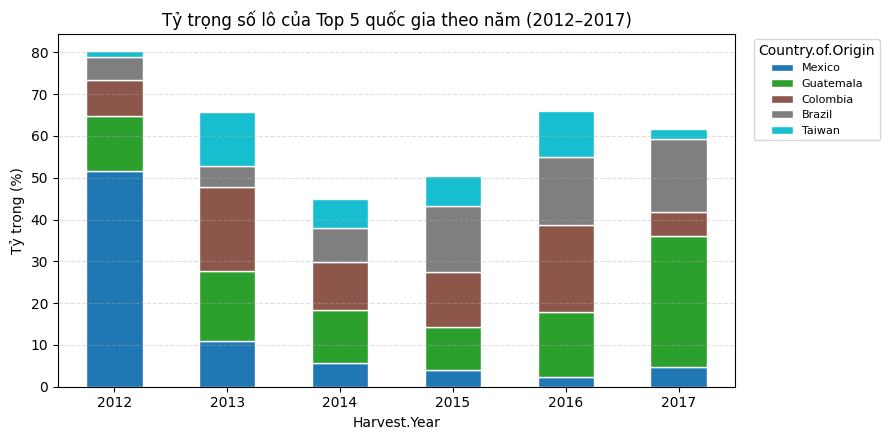

In [7]:
top5 = d["Country.of.Origin"].value_counts().head(5).index.tolist()
share = pd.crosstab(d["Harvest.Year"], d["Country.of.Origin"], normalize="index")[top5]
print("Top 5 quốc gia giai đoạn 2012–2017:", top5)
print("Tỷ trọng số lô theo năm (%):")
display((share * 100).round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
(share * 100).plot(kind="bar", stacked=True, ax=ax, colormap="tab10", edgecolor="white")
ax.set_title("Tỷ trọng số lô của Top 5 quốc gia theo năm (2012–2017)")
ax.set_xlabel("Harvest.Year")
ax.set_ylabel("Tỷ trọng (%)")
ax.legend(title="Country.of.Origin", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

So sánh độ dốc xu hướng theo năm (2012–2017) trước và sau kiểm soát cơ cấu quốc gia:


,Phiên bản,Độ dốc (điểm/năm),CI 95% thấp (điểm/năm),CI 95% cao (điểm/năm),CI chứa 0,Kết luận
0,Xu hướng gộp (Raw total_9),0.0827,0.0073,0.1313,False,CI không chứa 0 → Có bằng chứng xu hướng
1,Sau kiểm soát quốc gia (Adjusted),0.0326,-0.0102,0.0908,True,CI chứa 0 → Không đủ bằng chứng có xu hướng


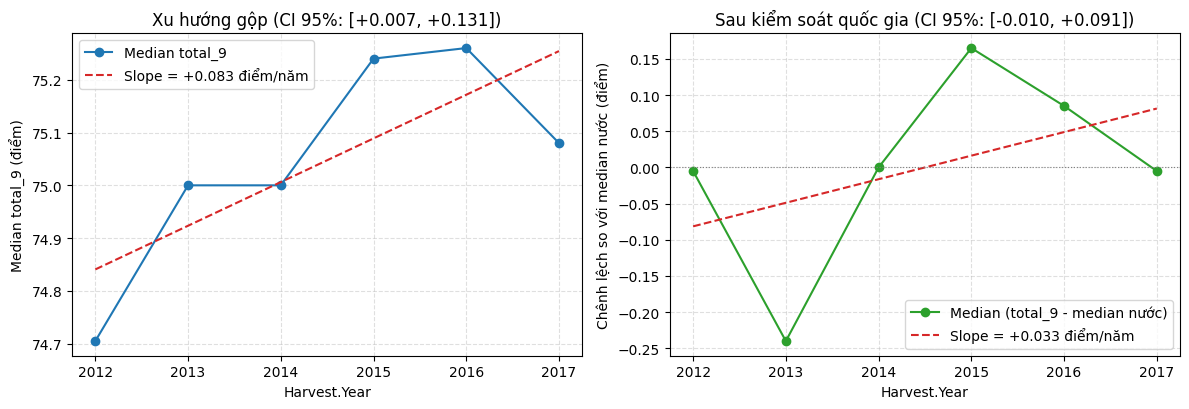

In [8]:
from src.stats import bootstrap_ci

# Phiên bản kiểm soát cơ cấu quốc gia: trừ median của từng nước
d["adj"] = d["total_9"] - d.groupby("Country.of.Origin")["total_9"].transform("median")
adj_by_year = d.groupby("Harvest.Year")["adj"].median()

def slope_of(sample, col="total_9"):
    med = sample.groupby("Harvest.Year")[col].median()
    return float(np.polyfit(med.index.astype(float), med.values, 1)[0])

slope_raw, (lo_raw, hi_raw) = bootstrap_ci(
    d, lambda s: slope_of(s, "total_9"), n_boot=2000, seed=RANDOM_STATE, strata="Harvest.Year"
)
slope_adj, (lo_adj, hi_adj) = bootstrap_ci(
    d, lambda s: slope_of(s, "adj"), n_boot=2000, seed=RANDOM_STATE, strata="Harvest.Year"
)

def interpret_ci(lo, hi):
    if lo <= 0 <= hi:
        return "CI chứa 0 → Không đủ bằng chứng có xu hướng"
    return "CI không chứa 0 → Có bằng chứng xu hướng"

comparison_df = pd.DataFrame([
    {
        "Phiên bản": "Xu hướng gộp (Raw total_9)",
        "Độ dốc (điểm/năm)": slope_raw,
        "CI 95% thấp (điểm/năm)": lo_raw,
        "CI 95% cao (điểm/năm)": hi_raw,
        "CI chứa 0": bool(lo_raw <= 0 <= hi_raw),
        "Kết luận": interpret_ci(lo_raw, hi_raw),
    },
    {
        "Phiên bản": "Sau kiểm soát quốc gia (Adjusted)",
        "Độ dốc (điểm/năm)": slope_adj,
        "CI 95% thấp (điểm/năm)": lo_adj,
        "CI 95% cao (điểm/năm)": hi_adj,
        "CI chứa 0": bool(lo_adj <= 0 <= hi_adj),
        "Kết luận": interpret_ci(lo_adj, hi_adj),
    },
])
print("So sánh độ dốc xu hướng theo năm (2012–2017) trước và sau kiểm soát cơ cấu quốc gia:")
display(comparison_df.round(4))

# Biểu đồ so sánh 2 phiên bản
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
yrs = overall.index.astype(float)

axes[0].plot(yrs, overall.values, marker="o", label="Median total_9")
p_raw = np.poly1d(np.polyfit(yrs, overall.values, 1))
axes[0].plot(yrs, p_raw(yrs), linestyle="--", color="tab:red", label=f"Slope = {slope_raw:+.3f} điểm/năm")
axes[0].set_title(f"Xu hướng gộp (CI 95%: [{lo_raw:+.3f}, {hi_raw:+.3f}])")
axes[0].set_xlabel("Harvest.Year")
axes[0].set_ylabel("Median total_9 (điểm)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

axes[1].plot(yrs, adj_by_year.values, marker="o", color="tab:green", label="Median (total_9 - median nước)")
p_adj = np.poly1d(np.polyfit(yrs, adj_by_year.values, 1))
axes[1].plot(yrs, p_adj(yrs), linestyle="--", color="tab:red", label=f"Slope = {slope_adj:+.3f} điểm/năm")
axes[1].axhline(0, color="gray", linewidth=0.8, linestyle=":")
axes[1].set_title(f"Sau kiểm soát quốc gia (CI 95%: [{lo_adj:+.3f}, {hi_adj:+.3f}])")
axes[1].set_xlabel("Harvest.Year")
axes[1].set_ylabel("Chênh lệch so với median nước (điểm)")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# TEST: Kiểm tra tỷ trọng top 5, độ dốc và bootstrap CI 95%
assert len(top5) == 5
assert (share.sum(axis=1) <= 1.0 + 1e-9).all(), "Tổng tỷ trọng top 5 mỗi năm không thể vượt 100%"
assert d["adj"].isna().sum() == 0, "Không được có NA ở biến adj"
assert lo_raw <= slope_raw <= hi_raw, "slope_raw phải nằm trong CI 95%"
assert lo_adj <= slope_adj <= hi_adj, "slope_adj phải nằm trong CI 95%"
print("All Q4 Country-Control (D4) & Bootstrap Slope CI (D5) # TEST checks passed!")

All Q4 Country-Control (D4) & Bootstrap Slope CI (D5) # TEST checks passed!


## 4. Results — Biểu đồ tổng hợp & Trả lời Q4

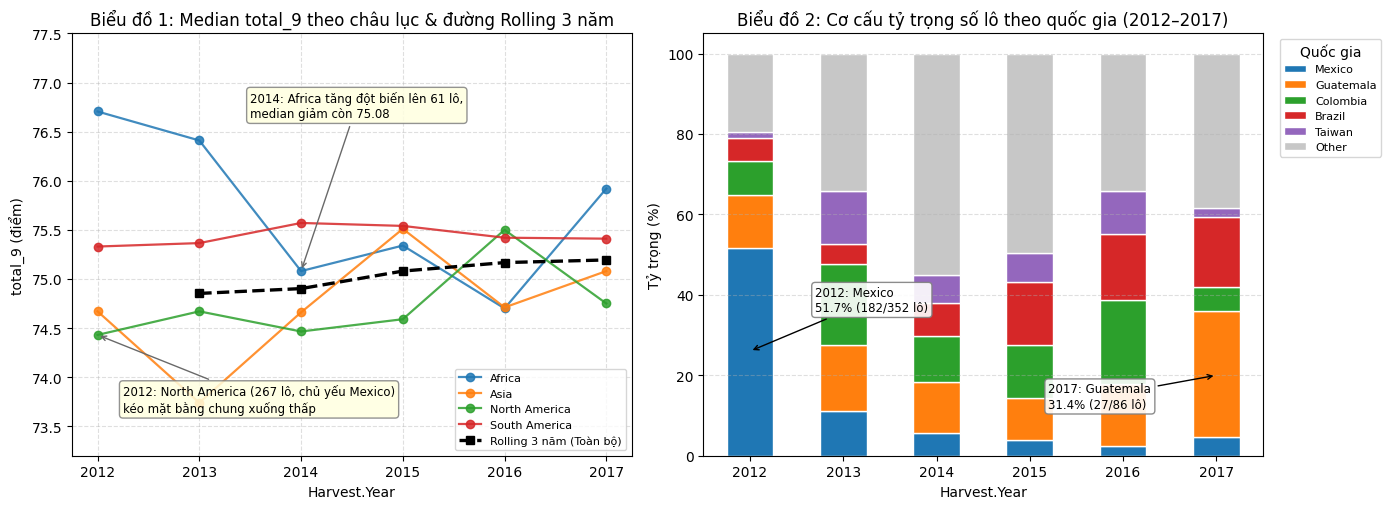

In [10]:
# Biểu đồ 1: Đường median theo năm của từng châu lục + đường rolling 3 năm (có annotate năm bất thường)
# Biểu đồ 2: Stacked bar tỷ trọng quốc gia theo năm (Top 5 + Other, có annotate năm bất thường)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# --- Panel 1 ---
yrs_int = overall_summary.index.astype(int)
for cont in ["Africa", "Asia", "North America", "South America"]:
    s_cont = pv["median"][cont]
    axes[0].plot(s_cont.index.astype(int), s_cont.values, marker="o", linewidth=1.6, alpha=0.85, label=cont)

# Đường rolling 3 năm toàn bộ
axes[0].plot(
    yrs_int,
    overall_summary["rolling_3y_mean"],
    color="black",
    linestyle="--",
    linewidth=2.4,
    marker="s",
    label="Rolling 3 năm (Toàn bộ)",
)

# Annotate các điểm bất thường
axes[0].annotate(
    "2012: North America (267 lô, chủ yếu Mexico)\nkéo mặt bằng chung xuống thấp",
    xy=(2012, pv["median"]["North America"].loc[2012]),
    xytext=(2012.25, 73.65),
    arrowprops=dict(arrowstyle="->", color="dimgray", lw=1.0),
    fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gray", alpha=0.85),
)
axes[0].annotate(
    "2014: Africa tăng đột biến lên 61 lô,\nmedian giảm còn 75.08",
    xy=(2014, pv["median"]["Africa"].loc[2014]),
    xytext=(2013.5, 76.65),
    arrowprops=dict(arrowstyle="->", color="dimgray", lw=1.0),
    fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gray", alpha=0.85),
)
axes[0].set_title("Biểu đồ 1: Median total_9 theo châu lục & đường Rolling 3 năm")
axes[0].set_xlabel("Harvest.Year")
axes[0].set_ylabel("total_9 (điểm)")
axes[0].set_ylim(73.2, 77.5)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(loc="lower right", fontsize=8)

# --- Panel 2 ---
share_full = share.copy()
share_full["Other"] = 1.0 - share_full.sum(axis=1)
(share_full * 100).plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#c7c7c7"],
    edgecolor="white",
)
axes[1].annotate(
    "2012: Mexico\n51.7% (182/352 lô)",
    xy=(0, 26),
    xytext=(0.7, 36),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
    fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)
axes[1].annotate(
    "2017: Guatemala\n31.4% (27/86 lô)",
    xy=(5, 20),
    xytext=(3.2, 12),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
    fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)
axes[1].set_title("Biểu đồ 2: Cơ cấu tỷ trọng số lô theo quốc gia (2012–2017)")
axes[1].set_xlabel("Harvest.Year")
axes[1].set_ylabel("Tỷ trọng (%)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Quốc gia", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### Trả lời câu hỏi Q4

- **Trước khi kiểm soát cơ cấu quốc gia (Xu hướng gộp):** Trong giai đoạn 2012–2017, điểm trung vị `total_9` có độ dốc tăng nhẹ **`+0.0827 điểm/năm`** (CI 95% bootstrap theo tầng: **`[+0.0073, +0.1313]` điểm/năm**, không chứa 0).
- **Sau khi kiểm soát cơ cấu quốc gia (trừ median từng quốc gia):** Độ dốc giảm xuống chỉ còn **`+0.0326 điểm/năm`** với CI 95% **`[-0.0102, +0.0908]` điểm/năm** (chứa 0). Do đó, **không đủ bằng chứng kết luận có xu hướng tăng hoặc giảm chất lượng nội tại theo thời gian**.
- **Ý nghĩa thực tiễn:** Xu hướng tăng nhẹ quan sát được ở chuỗi gộp chủ yếu đến từ **sự dịch chuyển cơ cấu quốc gia gửi mẫu** qua các năm (năm 2012 có tới 51,70% mẫu đến từ Mexico với mặt bằng điểm thấp hơn, sau đó giảm mạnh còn 2,33–4,65% trong giai đoạn 2016–2017, nhường chỗ cho tỷ trọng cao hơn từ Guatemala, Colombia và Brazil). Vì vậy, nhà rang xay và người mua không nên diễn giải chuỗi điểm gộp qua các năm là dấu hiệu chất lượng cà phê thế giới đang tăng đều, mà cần theo dõi chất lượng trong từng vùng/quốc gia cụ thể.
- **Hạn chế:** (1) Chuỗi thời gian ngắn, chỉ gồm **6 năm (2012–2017)**; (2) **Số lô mỗi năm không đều**, giảm dần từ 352 lô (2012) xuống 86 lô (2017), khiến độ bất định ở các năm cuối lớn hơn; (3) Dữ liệu CQI phản ánh các lô do nhà sản xuất/xuất khẩu tự nguyện gửi chấm điểm, không phải mẫu ngẫu nhiên đại diện toàn bộ sản lượng toàn cầu.